

# AI Programming with Python Final Exam

**Name: Md. Rezwan Zani**

**Course Email:**  rezwan.aaub@gmail.com


## End of Assignment

Before submitting:
- Must watch the Exam Instructions Video
- Run all cells from top to bottom.  
- Check that all answer sections are filled.  
- Instruction video অনুযায়ী আমাদের দেয়া Colab ফাইলটি থেকে প্রথম একটি Save copy in drive করে নিবা। এরপর Google colab এর মধ্যে কোডগুলো করবে এবং সেই ফাইলটি ‘Anyone with the link’ & ‘View’ Access দিয়ে ফাইলটির Shareble Link টি সাবমিট করবে।

# 0) Starter Code (Run First)

In [27]:
# You must run this code and use this dataset for all questions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
num_students = 50

# Student data
student_ids = np.arange(201, 201 + num_students)
student_ages = np.random.randint(15, 22, num_students)
student_scores = np.random.randint(40, 100, num_students)
student_attendance = np.random.randint(60, 100, num_students)  # percentage

departments_list = [
    "Science",
    "Commerce",
    "Arts",
    "Computer Science",
    "Mathematics",
    "English",
    "Physics",
    "Chemistry",
    "Biology",
    "Economics"
]

student_departments = np.random.choice(departments_list, num_students)

grade_conditions = [
    student_scores >= 80,
    (student_scores >= 65) & (student_scores < 80),
    (student_scores >= 50) & (student_scores < 65),
    student_scores < 50
]
grade_values = ["A", "B", "C", "F"]
student_grades = np.select(grade_conditions, grade_values, default="F")

# Create DataFrame
data = pd.DataFrame({
    "student_id": student_ids,
    "student_age": student_ages,
    "score": student_scores,
    "attendance": student_attendance,
    "department": student_departments,
    "grade": student_grades
})

# Save dataset
data.to_csv("school_data.csv", index=False)

# Question 01: [ Marks 10 ]

Use NumPy arrays from the score and attendance columns. Print both arrays and display:

* Data type
* Number of dimensions
* Shape
* Total number of elements

# Write Answer 01:


In [28]:
df = pd.read_csv("school_data.csv")
scores = np.array(df["score"])
attendance = np.array(df["attendance"])

print("Data type of scores:", type(scores))
print("Number of dimensions of scores:", scores.ndim)
print("Shape of scores:", scores.shape)
print("Total number of elements in scores:", scores.size)

print("Data type of attendance:", type(attendance))
print("Number of dimensions of attendance:", attendance.ndim)
print("Shape of attendance:", attendance.shape)
print("Total number of elements in attendance:", attendance.size)

Data type of scores: <class 'numpy.ndarray'>
Number of dimensions of scores: 1
Shape of scores: (50,)
Total number of elements in scores: 50
Data type of attendance: <class 'numpy.ndarray'>
Number of dimensions of attendance: 1
Shape of attendance: (50,)
Total number of elements in attendance: 50


# Question 02: [ Marks 10 ]

## Using NumPy functions on :

* Find the maximum and minimum score
* Calculate the average score
* Calculate the average attendance

Then, extract students who:

* Have a score greater than the average score

Print:

* The filtered score array

## Write Answer 02:


In [29]:
max_score = np.max(scores)
min_score = np.min(scores)
avg_score = np.mean(scores)

avg_attendance = np.mean(attendance)

print("Maximum score:", max_score)
print("Minimum score:", min_score)
print("Average score:", avg_score)
print("Average attendance:", avg_attendance)

more_than_avg_score = scores[scores > avg_score]
print("Scores greater than average score:", more_than_avg_score)

Maximum score: 99
Minimum score: 41
Average score: 67.3
Average attendance: 79.58
Scores greater than average score: [76 90 78 99 89 97 92 86 99 83 86 74 75 89 79 93 81 93 68 83 73 75 70 87]


# Question 03: [Marks 10]

##
Load the school_data.csv file into a Pandas DataFrame.

* Display the first 3 rows
* Show dataset information using .info()
* Display summary statistics using .describe()

Then filter the dataset to include only:

* student_id, student_age, department, grade

Select students whose age is between 16 and 20, sort them by student_id, and display the last 3 rows of the result.


## Write Answer 03:

In [30]:
school_data = pd.read_csv("school_data.csv")

school_data.info()
school_data.describe()

new_school_data = school_data.drop(columns=["score", "attendance"])

new_school_data = new_school_data[(new_school_data["student_age"] >= 16) & (new_school_data["student_age"] <= 20)].sort_values(by="student_id")

new_school_data.tail(3)




<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   student_id   50 non-null     int64
 1   student_age  50 non-null     int64
 2   score        50 non-null     int64
 3   attendance   50 non-null     int64
 4   department   50 non-null     str  
 5   grade        50 non-null     str  
dtypes: int64(4), str(2)
memory usage: 2.5 KB


,student_id,student_age,department,grade
45,246,18,Biology,C
47,248,18,Science,A
49,250,17,Economics,F



# Question 04: [ Marks 10 ]

##
Using .loc:

* Increase the score by 10% for students in "Computer Science" and "Mathematics" departments
* Increase the score by 5% for all other departments
* Cap the score at 100 (no score should exceed 100 after the raise)

Then print a DataFrame that includes:

* student_id, department, previous_score, new_score, score_increase


## Write Answer 04:

In [31]:
target_depts = school_data["department"].isin(["Computer Science", "Mathematics"])

school_data.loc[target_depts, "new_score"] = school_data.loc[target_depts, "score"] * 1.1
school_data.loc[~target_depts, "new_score"] = school_data.loc[~target_depts, "score"] * 1.05

school_data.loc[school_data["new_score"] > 100, "new_score"] = 100

school_data["score_increased"] = school_data["new_score"] - school_data["score"]
school_data = school_data.rename(columns={"score": "old_score"})

school_data

,student_id,student_age,old_score,attendance,department,grade,new_score,score_increased
0,201,21,76,73,Physics,B,79.80,3.80
1,202,18,90,82,Physics,A,94.50,4.50
2,203,19,46,99,Biology,F,48.30,2.30
3,204,21,60,80,Economics,C,63.00,3.00
4,205,17,48,75,Economics,F,50.40,2.40
5,206,19,78,77,Arts,B,81.90,3.90
6,207,19,57,83,Physics,C,59.85,2.85
7,208,21,43,85,Science,F,45.15,2.15
8,209,16,64,84,Computer Science,C,70.40,6.40
9,210,17,99,88,Computer Science,A,100.00,1.00


# Question 05: [ Marks 10 ]

Using Matplotlib, create a bar chart that shows the average score per department.

* X-axis: Department names
* Y-axis: Average score
* Add a title: "Average Score by Department"
* Display the chart

## Answer 05:

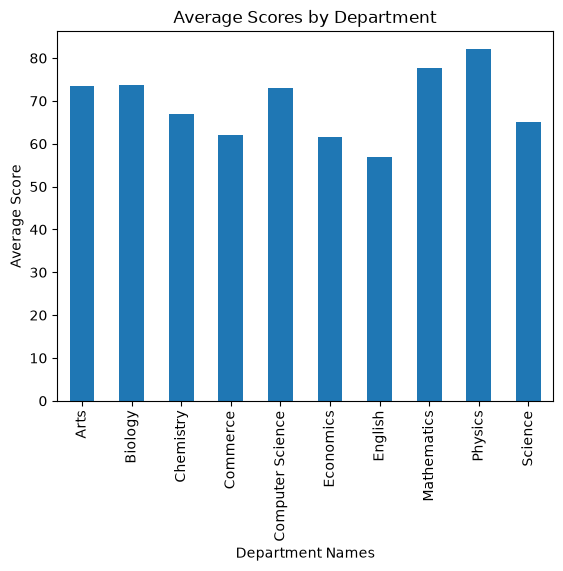

In [42]:
dept_avg_scores = school_data.groupby("department")["new_score"].mean().reset_index()

ax = dept_avg_scores.plot(kind="bar", x="department", y="new_score", legend=False);
ax.set_ylabel("Average Score");
ax.set_xlabel("Department Names");
ax.set_title("Average Scores by Department");

# Question 06: [ Marks 10 ]

Using Matplotlib, create a histogram of the score column.

* Use 10 bins
* Add a title: "Distribution of Student Scores"
* Label X-axis as "Score" and Y-axis as "Number of Students"
* Display the chart

## Answer 06:

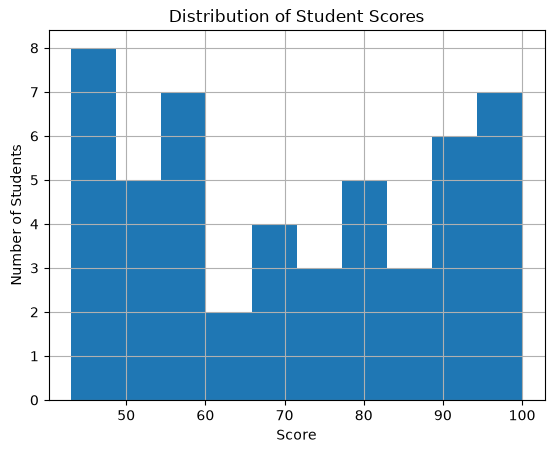

In [45]:
ax = school_data['new_score'].hist(bins=10)
ax.set(xlabel="Score",
       ylabel="Number of Students",
       title="Distribution of Student Scores");

# Question 07: [ Marks 10 ]

Using Matplotlib, create a scatter plot to visualize the relationship between attendance and score.

* X-axis: Attendance (%)
* Y-axis: Score
* Add a title: "Attendance vs Score"
* Label both axes properly
* Display the chart

## Answer 07:


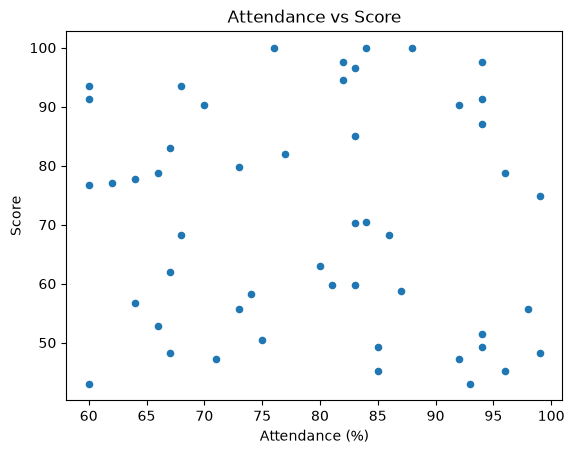

In [51]:
ax = school_data.plot(kind="scatter", x="attendance", y="new_score")
ax.set(xlabel="Attendance (%)",
       ylabel="Score",
       title="Attendance vs Score");


# Question 08: [ Marks 10 ]

Using Seaborn, create a boxplot / barplot that shows the distribution of score across different grade categories.

* X-axis: Grade
* Y-axis: Score
* Add a title: "Score Distribution by Grade"
* Display the chart

## Answer 08:

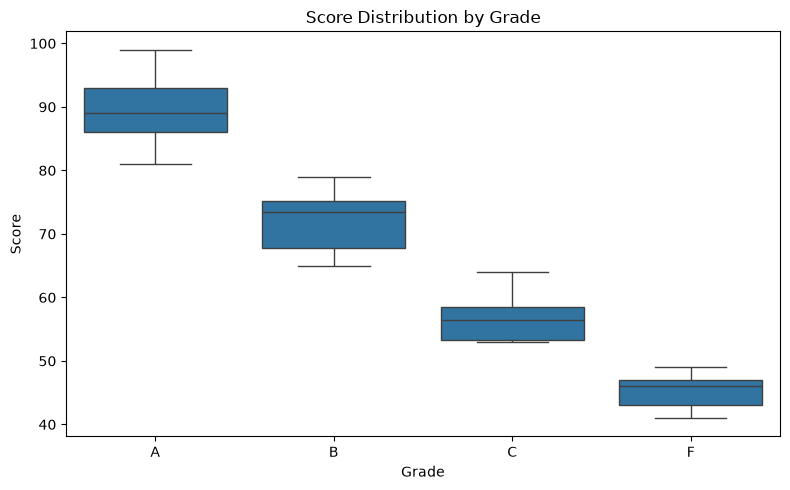

In [62]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=school_data, x='grade', order=["A", "B", "C", "F"], y='old_score')

plt.title('Score Distribution by Grade')
plt.xlabel('Grade')
plt.ylabel('Score')
plt.tight_layout()
plt.show()

# Question 09: [ Marks 10 ]

Using Seaborn, create a countplot showing the number of students in each department.

* Add a title: "Number of Students per Department"
* Display the chart

# Write Answer 09:

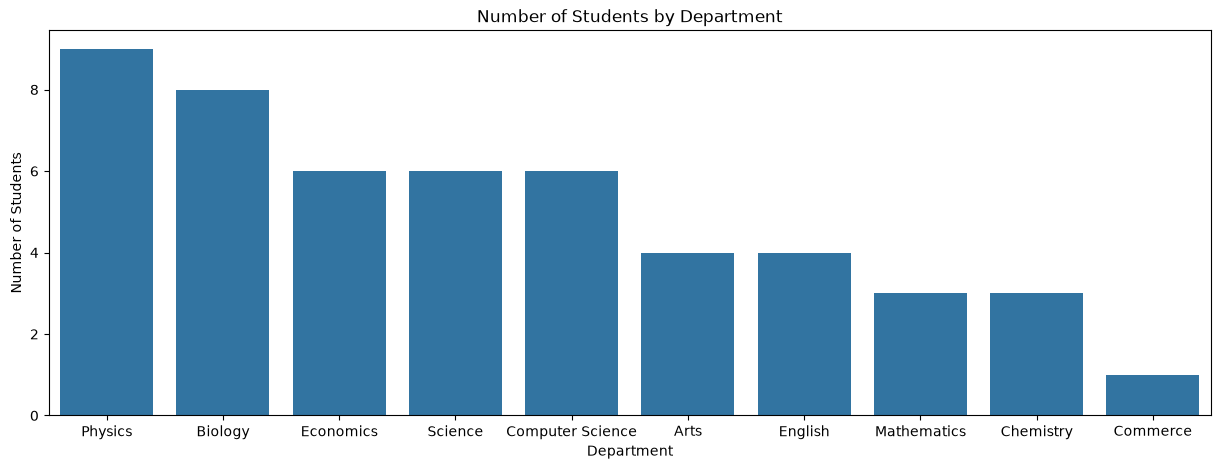

In [69]:
plt.figure(figsize=(15, 5))

sns.countplot(data=school_data, x="department", order=school_data['department'].value_counts().index)
plt.title('Number of Students by Department')
plt.xlabel('Department')
plt.ylabel('Number of Students')
plt.show()

# Question 10: [ Marks 10 ]

create a scatter plot showing attendance vs score.

* Color the points by department
* Add a title: "Attendance vs Score by Department"
* Label X-axis as "Attendance (%)" and Y-axis as "Score"
* Display the chart

# Write Answer 10:

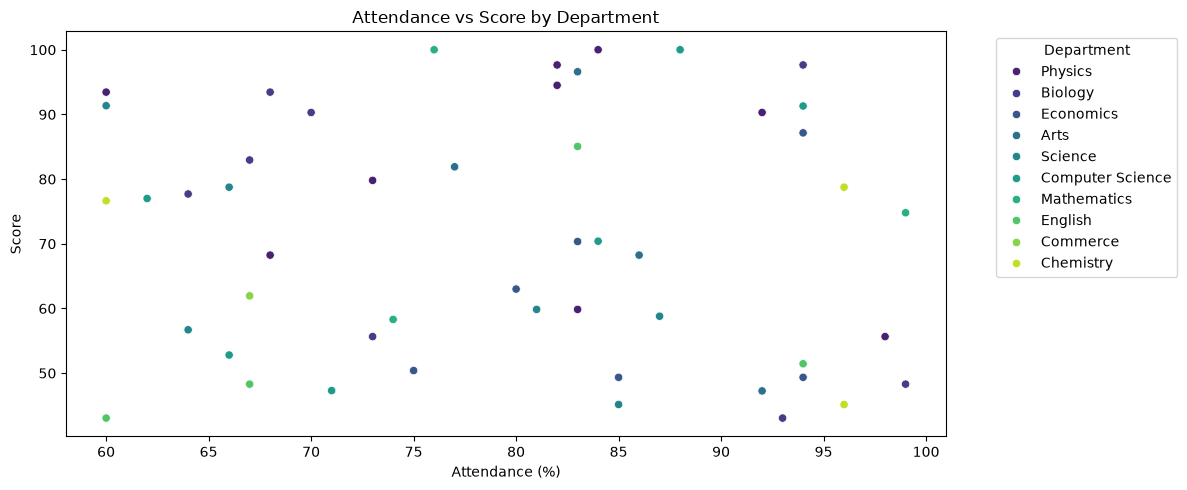

In [72]:
plt.figure(figsize=(12, 5))

sns.scatterplot(data=school_data, x="attendance", y="new_score", hue="department", palette='viridis')
plt.title('Attendance vs Score by Department')
plt.xlabel('Attendance (%)')
plt.ylabel('Score')
plt.legend(title='Department', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()